# [11.6] Feature Manifolds - Days, Months, Space and Time (exercises)

> **Colab: [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter11_representation_geometry/exercises/part6_feature_manifolds/11.6_Feature_Manifolds_Days_Months_Space_and_Time_exercises.ipynb)
> | [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter11_representation_geometry/exercises/part6_feature_manifolds/11.6_Feature_Manifolds_Days_Months_Space_and_Time_solutions.ipynb)**

> **Prediction practice: [start the guided workbook](../../../mastery_hub/units/extension_predictions/exercises.ipynb#section-11-6) before viewing this lesson's results.**
> Record a forecast, confidence and reasoning, then compare controls and predict a changed case. These reference-rich lessons support guided practice; prior exposure is not scored as unseen mastery.

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

# Introduction

Tuesday and Thursday are two days apart. If weekdays form a circle in a hidden state,
should moving the Tuesday point toward Thursday make *every* weekday advance by two days?
And if seven dots look perfectly circular in a two-dimensional plot, do they necessarily
have cyclic geometry in the full representation?

By the end of this notebook, you will have shown that **a convincing 2D ring needs both
high-dimensional and causal checks** in a constructed calendar organism. Your primary
figure places a real cyclic code beside an equally pretty projection of seven equidistant
one-hot states, then compares circular rotation with a single chord and a matched-size
orthogonal intervention. It ends in decoded weekday tokens, not just a feature cloud.

Prerequisites: original ARENA 0.1/0.3 (arrays and least squares), 1.2 (residual streams and
interventions), and 11.1 (PCA and controls). The entire default lesson uses deterministic
NumPy float64 CPU arrays; it fits small linear probes but loads no model or tokenizer.
The calendar and place/date representations are *constructed*, so their known geometry
provides ground truth rather than evidence of a learned LLM world model.

We keep all configured families visible: `representation.feature_manifolds`,
`representation.days_months_space_time` and `world.microscope_ai`. Here a “microscope”
means using a probe residual to propose and test a hypothesis about a known small organism.
Native weekday/month interventions, place/date activation extraction, feature irreducibility
tests on pretrained models and novel scientific concept discovery remain pending.

## Content & Learning Objectives

### 1️⃣ Build a cyclic representation

Construct day and month codes, embed them in a larger state, and distinguish a two-dimensional
linear span from a one-dimensional curved path inside that span.

> ##### Learning Objectives
>
> - Implement cyclic coordinates, contextual embedding and PCA.
> - Fit a labeled Fourier plane and compare subspaces without relying on axis signs.

### 2️⃣ Audit a suspicious projection

Produce a perfect-looking ring from a noncyclic simplex, then inspect the distances and
neighborhoods the plot left out.

> ##### Learning Objectives
>
> - Quantify distance distortion, cyclic-neighbor agreement and captured energy.
> - Distinguish label-chosen views from independent evidence for topology.

### 3️⃣ Turn Tuesday into Thursday

Rotate only the identified calendar plane, preserve the orthogonal state, and decode the
result. Compare it with a one-prompt chord shift and a displacement-matched control.

> ##### Learning Objectives
>
> - Implement a plane rotation, token readout and single-chord translation.
> - Test every weekday/offset pair rather than trusting one successful example.

### 4️⃣ Probe space and time, then inspect residuals

Fit a frozen affine place/date probe on one grid, evaluate new coordinates, and test a
candidate explanation for a remaining interaction feature.

> ##### Learning Objectives
>
> - Implement an affine probe, MSE and residual calculation with frozen fits.
> - Separate an interpretable residual hypothesis from a validated scientific discovery.

### ☆ Bonus

Connect the exact CPU organism to the primary LLM papers and plan a native follow-up.

## Setup code

Use the existing checkout environment and save your copy beside `tests.py`. No UMAP,
t-SNE, remote dataset or model download is needed. TRAIN and evaluated context values below
are named roles in a repeatedly inspected public teaching fixture. They are not untouched
evaluation evidence. The small fitted arrays are deliberately easy to inspect row by row.

In [ ]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

chapter = "chapter11_representation_geometry"
section = "part6_feature_manifolds"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
section_dir = exercises_dir / section
if str(exercises_dir) not in sys.path:
    sys.path.insert(0, str(exercises_dir))
import part6_feature_manifolds.tests as tests
import part6_feature_manifolds.utils as utils
MAIN = __name__ == "__main__"
np.set_printoptions(precision=4, suppress=True)

# 1️⃣ Build a cyclic representation

> ##### Learning Objectives
>
> - Implement cyclic coordinates, contextual embedding and PCA.
> - Fit a labeled Fourier plane and compare subspaces without relying on axis signs.

## Direction, plane, ring and manifold

A direction is one vector. A plane is a two-dimensional linear subspace. A circle is a
curved one-dimensional path *inside* a plane. Its samples span two linear dimensions even
though one continuous angle parameter determines a point. Seven weekday samples alone do
not prove the presence of a continuous manifold; here the continuous generating equation
is given, so the relationship is known rather than inferred from seven dots.

Cosine alone is ambiguous: days equally far clockwise and anticlockwise from Monday have
the same cosine coordinate. The sine coordinate resolves that ambiguity. This is a useful
example of why “feature” need not mean a single scalar direction. It is not a demonstration
of the full irreducibility criteria used by Engels and colleagues, which concern the
distribution's decomposition into independent or non-co-occurring lower-dimensional parts.

Our organism embeds $(\cos\theta,\sin\theta)$ in six dimensions and adds context along an
orthogonal nuisance axis. Its decoder reads the calendar plane and emits the nearest day
token. All of those mechanisms remain visible, so a later intervention can be checked
against a known cause of the token output.

Return `(n,2)` coordinates for integer or real indices `(n,)` and a positive period $P$:
$\theta_i=2\pi i/P$, $c_i=(\cos\theta_i,\sin\theta_i)$. The first day is Monday=0;
January=0 when $P=12$. Real-valued indices let you inspect the underlying continuous path,
but the named tokens remain discrete. Index `P` must coincide with index zero.

### Exercise - implement `cyclic_coordinates`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10 minutes on this exercise.
> ```

Implement `cyclic_coordinates` with the shapes, equation, edge cases and return contract described above.

In [ ]:
def cyclic_coordinates(indices, period):
    raise NotImplementedError()


tests.test_cyclic_coordinates(cyclic_coordinates)

<details>
<summary>Hint</summary>

Stack cosine and sine on the last axis, not as two batch rows.

</details>

<details>
<summary>Help - what does this check establish?</summary>

A ring is periodic. Treating weekday labels as an ordinary increasing scalar makes Sunday and Monday artificially far apart.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_cyclic_coordinates passed!</pre>

</details>


<details><summary>Solution</summary>

```python
def cyclic_coordinates(indices, period):
    angles = 2. * np.pi * np.asarray(indices) / period
    return np.stack([np.cos(angles), np.sin(angles)], axis=-1)
```
</details>

For coordinates `(n,2)`, a row-basis `(2,d)` and nuisance array `(n,d)`, return
$H=CB+N$. Basis rows are orthonormal in the main fixture and nuisance is orthogonal to
their span. You may assume compatible shapes. This is a known feature-generating equation,
not a learned representation. Its explicit nuisance term lets us test whether a probe
depends on context rather than calendar identity.

### Exercise - implement `embed_manifold`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10 minutes on this exercise.
> ```

Implement `embed_manifold` with the shapes, equation, edge cases and return contract described above.

In [ ]:
def embed_manifold(coordinates, basis, nuisance):
    raise NotImplementedError()


tests.test_embed_manifold(embed_manifold)

<details>
<summary>Hint</summary>

The feature coefficients multiply basis rows; keep the batch dimension first.

</details>

<details>
<summary>Help - what does this check establish?</summary>

Knowing the embedding gives us an exact control for geometry and causal arithmetic, but says nothing about spontaneous emergence in an LLM.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_embed_manifold passed!</pre>

</details>


<details><summary>Solution</summary>

```python
def embed_manifold(coordinates, basis, nuisance):
    return coordinates @ basis + nuisance
```
</details>

## Fit a view using TRAIN only

Return the TRAIN mean `(d,)` and the first `rank` right singular vectors `(rank,d)` of
the centered data. Do not refit the center or axes on evaluated contexts. The two circular
directions have equal variance, so their individual PCA axes can rotate or flip signs
without changing the plane. A test that insists on a particular axis sign would reject
correct solutions; our oracle compares the projector $B^TB$ instead.

### Exercise - implement `pca_plane`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10 minutes on this exercise.
> ```

Implement `pca_plane` with the shapes, equation, edge cases and return contract described above.

In [ ]:
def pca_plane(hidden, rank=2):
    raise NotImplementedError()


tests.test_pca_plane(pca_plane)

<details>
<summary>Hint</summary>

For rows as observations, the basis is in `Vh`, not the left singular vectors.

</details>

<details>
<summary>Help - what does this check establish?</summary>

Stable subspaces and unstable plotted axes can coexist. Sign changes alone are not evidence that the feature vanished.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_pca_plane passed!</pre>

</details>


<details><summary>Solution</summary>

```python
def pca_plane(hidden, rank=2):
    center = hidden.mean(axis=0)
    _, _, right = np.linalg.svd(hidden - center, full_matrices=False)
    return center, right[:rank]
```
</details>

## Give the circle an orientation tied to labels

PCA identifies a plane but not which angle means Tuesday. Fit the affine first harmonic
$H_i=b+\cos(2\pi i/P)B_0+\sin(2\pi i/P)B_1$ using least squares. Inputs are
hidden states `(n,d)`, their calendar indices `(n,)` and period. Return `center: (d,)`
and coefficient rows `(2,d)`. These are labeled Fourier coefficients, not an unsupervised
discovery. They need not be orthonormal for arbitrary data; inspect that condition before
using the rotation formula in Part 3. Our known circular fixture satisfies it.

### Exercise - implement `fit_fourier_plane`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10 minutes on this exercise.
> ```

Implement `fit_fourier_plane` with the shapes, equation, edge cases and return contract described above.

In [ ]:
def fit_fourier_plane(hidden, indices, period):
    raise NotImplementedError()


tests.test_fit_fourier_plane(fit_fourier_plane)

<details>
<summary>Hint</summary>

Include the intercept as the first design column, then preserve cosine/sine order.

</details>

<details>
<summary>Help - what does this check establish?</summary>

A label-fitted circle must be evaluated on frozen new contexts and controlled interventions; its attractive training plot is not independent confirmation.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_fit_fourier_plane passed!</pre>

</details>


<details><summary>Solution</summary>

```python
def fit_fourier_plane(hidden, indices, period):
    design = np.column_stack([np.ones(len(indices)), cyclic_coordinates(indices, period)])
    coefficients = np.linalg.lstsq(design, hidden, rcond=None)[0]
    return coefficients[0], coefficients[1:]
```
</details>

For two orthonormal row-bases `(k,d)` of equal rank, return
$\|B_1B_2^T\|_F^2/k$. It equals 1 for the same subspace, including sign flips and
in-plane rotations, and 0 for orthogonal subspaces. Use it to compare fitted planes across
context subsets. A high overlap says the *span* is stable; it does not calibrate the day
phase or show that the model uses the plane for an answer.

### Exercise - implement `subspace_overlap`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10 minutes on this exercise.
> ```

Implement `subspace_overlap` with the shapes, equation, edge cases and return contract described above.

In [ ]:
def subspace_overlap(first, second):
    raise NotImplementedError()


tests.test_subspace_overlap(subspace_overlap)

<details>
<summary>Hint</summary>

Square all entries of the cross-Gram matrix before summing.

</details>

<details>
<summary>Help - what does this check establish?</summary>

Comparing PCA vectors elementwise would confound arbitrary basis orientation with genuine subspace change.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_subspace_overlap passed!</pre>

</details>


<details><summary>Solution</summary>

```python
def subspace_overlap(first, second):
    return np.sum((first @ second.T)**2) / len(first)
```
</details>

In [ ]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_ids = np.repeat(np.arange(7), 2)
context = np.tile(np.array([-.3, .3]), 7)
basis = np.array([[1., 0., 1., 0., 0., 0.], [0., 1., 0., 1., 0., 0.]]) / np.sqrt(2.)
nuisance = np.zeros((14, 6)); nuisance[:, 4] = context
train_hidden = embed_manifold(cyclic_coordinates(day_ids, 7), basis, nuisance)
evaluated_nuisance = nuisance.copy(); evaluated_nuisance[:, 4] *= 3.
evaluated_hidden = embed_manifold(cyclic_coordinates(day_ids, 7), basis, evaluated_nuisance)
pca_center, pca_basis = pca_plane(train_hidden)
fourier_center, fitted_basis = fit_fourier_plane(train_hidden, day_ids, 7)
np.testing.assert_allclose(fitted_basis @ fitted_basis.T, np.eye(2), atol=1e-12)
print("PCA / true plane overlap:", subspace_overlap(pca_basis, basis))
print("Fourier / true plane overlap:", subspace_overlap(fitted_basis, basis))
_, single_context_basis = pca_plane(train_hidden[::2])
print("Across-context fitted plane overlap:", subspace_overlap(pca_basis, single_context_basis))
print("Monday, Tuesday, Thursday coordinates:")
print(cyclic_coordinates(np.array([0, 1, 3]), 7))
month_ids = np.arange(12)
month_hidden = embed_manifold(cyclic_coordinates(month_ids, 12), basis, np.zeros((12, 6)))
print("Month coordinates have shape:", cyclic_coordinates(month_ids, 12).shape)

<details><summary>Expected output</summary>

The two plane overlaps are 1 up to float64 rounding. Monday, Tuesday and Thursday have
coordinates `[1,0]`, approximately `[0.6235,0.7818]` and `[-0.9010,0.4339]`. The month
coordinate array has shape `(12,2)`. A plane can be shared by several cyclic variables;
its interpretation depends on context, phase calibration and the decoder.

</details>

## Summary of 1️⃣

You have a known cyclic organism, an unlabeled variance plane and a labeled phase-calibrated
plane. Keep their different sources of information visible in the next comparison.

# 2️⃣ Audit a suspicious projection

> ##### Learning Objectives
>
> - Quantify distance distortion, cyclic-neighbor agreement and captured energy.
> - Distinguish label-chosen views from independent evidence for topology.

## Inspect what the plot cannot show

Return all Euclidean distances `(n,n)` between rows of `(n,d)`. A direct broadcasted
difference is fine at this scale. Every off-diagonal distance between distinct one-hot
vectors is $\sqrt2$: they are equally near, so there is no preferred cyclic neighbor.
Yet multiplying those vectors by a matrix whose rows are arranged on a circle draws a
perfect ring. The 2D image alone cannot tell you which representation you started from.

### Exercise - implement `pairwise_distances`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10 minutes on this exercise.
> ```

Implement `pairwise_distances` with the shapes, equation, edge cases and return contract described above.

In [ ]:
def pairwise_distances(hidden):
    raise NotImplementedError()


tests.test_pairwise_distances(pairwise_distances)

<details>
<summary>Hint</summary>

The two batch axes should index two different rows; sum only over the final feature axis.

</details>

<details>
<summary>Help - what does this check establish?</summary>

A good-looking view may discard exactly the directions that distinguish nearby from distant examples.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_pairwise_distances passed!</pre>

</details>


<details><summary>Solution</summary>

```python
def pairwise_distances(hidden):
    differences = hidden[:, None, :] - hidden[None, :, :]
    return np.sqrt(np.sum(differences**2, axis=-1))
```
</details>

For full and projected distance matrices of the same shape, return normalized distortion
$\sqrt{\sum_{i<j}(D_{ij}-d_{ij})^2/\sum_{i<j}D_{ij}^2}$. Use only unordered distinct
pairs. The fixtures have positive denominator. There is no fitted rescaling in this
definition, so preserve the displayed units; if you later fit a scale, name that different
metric and state which data estimated it. Distortion zero means these distances survived,
not that the selected representation has a unique topology.

### Exercise - implement `distance_stress`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10 minutes on this exercise.
> ```

Implement `distance_stress` with the shapes, equation, edge cases and return contract described above.

In [ ]:
def distance_stress(original, projected):
    raise NotImplementedError()


tests.test_distance_stress(distance_stress)

<details>
<summary>Hint</summary>

An off-diagonal upper-triangle mask avoids counting symmetric pairs twice.

</details>

<details>
<summary>Help - what does this check establish?</summary>

We audit quantitative information lost by the view instead of scoring the visual prettiness of the ring.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_distance_stress passed!</pre>

</details>


<details><summary>Solution</summary>

```python
def distance_stress(original, projected):
    mask = np.triu(np.ones_like(original, dtype=bool), k=1)
    return np.sqrt(np.sum((original[mask] - projected[mask])**2) / np.sum(original[mask]**2))
```
</details>

For each row, take its two closest *other* rows and count how many labels are its cyclic
predecessor or successor. Return the fraction over `2*n` neighbor slots. Use a stable sort;
ties are resolved by original row order. Indices are unique calendar positions in this
audit, not repeated context rows. Ties in a simplex are a substantive absence of neighbor
information; do not break them using the answer labels you hope to recover.

### Exercise - implement `cyclic_neighbor_score`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10 minutes on this exercise.
> ```

Implement `cyclic_neighbor_score` with the shapes, equation, edge cases and return contract described above.

In [ ]:
def cyclic_neighbor_score(distances, indices, period):
    raise NotImplementedError()


tests.test_cyclic_neighbor_score(cyclic_neighbor_score)

<details>
<summary>Hint</summary>

Remove the row itself explicitly rather than assuming it is the first element after a tie.

</details>

<details>
<summary>Help - what does this check establish?</summary>

Choosing cyclic neighbors to break a tie would manufacture the very structure the audit is supposed to test.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_cyclic_neighbor_score passed!</pre>

</details>


<details><summary>Solution</summary>

```python
def cyclic_neighbor_score(distances, indices, period):
    scores = []
    for row, label in enumerate(indices):
        order = np.argsort(distances[row], kind="stable")
        nearest = [index for index in order if index != row][:2]
        wanted = {(int(label)-1) % period, (int(label)+1) % period}
        scores.extend(int(indices[index]) in wanted for index in nearest)
    return np.mean(scores)
```
</details>

For centered hidden states `(n,d)` and an orthonormal row-basis `(k,d)`, return the fraction
of total squared energy captured by the projection. Compute the center within the given
audit dataset; this descriptive energy diagnostic is distinct from applying a fitted
probe's TRAIN preprocessing. The centered simplex has rank six; a rank-two projection
therefore misses most of its energy even when the selected view forms a perfect circle.

### Exercise - implement `energy_fraction`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10 minutes on this exercise.
> ```

Implement `energy_fraction` with the shapes, equation, edge cases and return contract described above.

In [ ]:
def energy_fraction(hidden, basis):
    raise NotImplementedError()


tests.test_energy_fraction(energy_fraction)

<details>
<summary>Hint</summary>

An orthonormal projection preserves the norm of its coordinate representation.

</details>

<details>
<summary>Help - what does this check establish?</summary>

Energy and label fit provide different evidence: a low-energy label-fitted view can look beautifully structured.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_energy_fraction passed!</pre>

</details>


<details><summary>Solution</summary>

```python
def energy_fraction(hidden, basis):
    centered = hidden - hidden.mean(axis=0)
    return np.sum((centered @ basis.T)**2) / np.sum(centered**2)
```
</details>

In [ ]:
calendar_centroids = cyclic_coordinates(np.arange(7), 7) @ basis
calendar_view = calendar_centroids @ fitted_basis.T
simplex = np.eye(7)
chosen_projection = cyclic_coordinates(np.arange(7), 7) * np.sqrt(2./7.)
# Columns are orthonormal, but they were deliberately chosen using day labels.
simplex_view = simplex @ chosen_projection
full_circle_d = pairwise_distances(calendar_centroids)
full_simplex_d = pairwise_distances(simplex)
print("Calendar distance stress:", distance_stress(full_circle_d, pairwise_distances(calendar_view)))
print("Simplex distance stress:", distance_stress(full_simplex_d, pairwise_distances(simplex_view)))
print("Cyclic neighbor scores, calendar / simplex:",
      cyclic_neighbor_score(full_circle_d, np.arange(7), 7),
      cyclic_neighbor_score(full_simplex_d, np.arange(7), 7))
print("Simplex rank-two captured energy:", energy_fraction(simplex, chosen_projection.T))
reversed_labels = np.array([0, 2, 4, 6, 1, 3, 5])
print("Calendar shuffled-label neighbor score:", cyclic_neighbor_score(full_circle_d, reversed_labels, 7))

## Forecast before intervening

The two views in the forthcoming figure are both exact rings. Predict which one retains
its cyclic neighbors in the full state space. Then predict whether a single translation
that maps Tuesday to Thursday will advance every other weekday by two days. Include a
reason grounded in geometry, not the appearance of a scatter plot.

<details><summary>Help - are hand-picked projection controls unfair?</summary>

They answer an existence question: can a perfect ring be a projection artifact? Yes,
because this control produces one without cyclic full-space distances. It does not show
that PCA, UMAP or any published analysis necessarily makes this error. To assess a real
analysis, record its projection selection and inspect held-out data, distances, stability
and interventions. A deliberately adversarial control clarifies what the image alone
cannot establish.

</details>

## Summary of 2️⃣

You have measured distances, tie-aware neighbors and energy outside the chosen view.
None is replaced by the presence of a clear circle on a screen.

# 3️⃣ Turn Tuesday into Thursday

> ##### Learning Objectives
>
> - Implement a plane rotation, token readout and single-chord translation.
> - Test every weekday/offset pair rather than trusting one successful example.

## Change an angle while preserving the rest of the state

Inputs are hidden states `(n,d)`, an **orthonormal and phase-calibrated** row-basis `(2,d)`
and an angle delta. Extract $C=HB^T$, rotate the coordinate rows by
$R=\begin{pmatrix}\cos\delta&\sin\delta\\-\sin\delta&\cos\delta\end{pmatrix}$,
then return $H-CB+(CR)B$. This preserves the component orthogonal to the plane.
With row-vector coordinates, transposing that rotation convention reverses time.

This is a rotation in a known feature plane, not fixed-vector activation addition. Check
orthonormality before using it on a fitted plane. An ellipse or a nonorthogonal basis
requires an explicit metric/coordinate treatment; blindly applying the same matrix would
be a different intervention.

### Exercise - implement `rotate_in_plane`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10 minutes on this exercise.
> ```

Implement `rotate_in_plane` with the shapes, equation, edge cases and return contract described above.

In [ ]:
def rotate_in_plane(hidden, basis, delta):
    raise NotImplementedError()


tests.test_rotate_in_plane(rotate_in_plane)

<details>
<summary>Hint</summary>

Subtract only the old plane component, then add its rotated replacement.

</details>

<details>
<summary>Help - what does this check establish?</summary>

Zeroing the whole state before writing the circle would also destroy contextual information, creating a confounded intervention.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_rotate_in_plane passed!</pre>

</details>


<details><summary>Solution</summary>

```python
def rotate_in_plane(hidden, basis, delta):
    coordinates = hidden @ basis.T
    rotation = np.array([[np.cos(delta), np.sin(delta)], [-np.sin(delta), np.cos(delta)]])
    return hidden - coordinates @ basis + (coordinates @ rotation) @ basis
```
</details>

## Turn the state into a visible token

The organism has one prototype per named calendar token. Project hidden states into the
known decoder basis and dot them with the `(period,2)` cyclic prototypes. Return the
highest-scoring token index `(n,)`. `np.argmax` breaks exact ties by the lowest index.
This readout is part of the declared organism, fixed independently of the fitted probe.
In a native LLM you must read actual model logits at the chosen answer position instead.

### Exercise - implement `decode_cycle`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10 minutes on this exercise.
> ```

Implement `decode_cycle` with the shapes, equation, edge cases and return contract described above.

In [ ]:
def decode_cycle(hidden, decoder_basis, period):
    raise NotImplementedError()


tests.test_decode_cycle(decode_cycle)

<details>
<summary>Hint</summary>

The output is a token index, not the largest coordinate of a two-dimensional vector.

</details>

<details>
<summary>Help - what does this check establish?</summary>

A causal test needs an outcome beyond the probe itself. Here the calendar-token decoder supplies that outcome.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_decode_cycle passed!</pre>

</details>


<details><summary>Solution</summary>

```python
def decode_cycle(hidden, decoder_basis, period):
    coordinates = hidden @ decoder_basis.T
    prototypes = cyclic_coordinates(np.arange(period), period)
    return np.argmax(coordinates @ prototypes.T, axis=-1)
```
</details>

## One successful prompt does not specify the global computation

Compute the chord from `source_index` to `target_index` on the given period's circle,
embed it with the row-basis, and add that **same vector** to every input hidden state.
For the selected source, the intervention lands exactly on the selected target. Other
points receive a translation rather than a rotation. Return a new `(n,d)` array.
We will use Tuesday=1 and Thursday=3, then test all seven weekdays.

### Exercise - implement `chord_shift`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10 minutes on this exercise.
> ```

Implement `chord_shift` with the shapes, equation, edge cases and return contract described above.

In [ ]:
def chord_shift(hidden, basis, period, source_index, target_index):
    raise NotImplementedError()


tests.test_chord_shift(chord_shift)

<details>
<summary>Hint</summary>

A chord depends on the chosen start point; a rotation angle specifies a global action.

</details>

<details>
<summary>Help - what does this check establish?</summary>

A fixed activation direction may produce an appealing one-prompt edit without implementing the intended operation over the whole feature.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_chord_shift passed!</pre>

</details>


<details><summary>Solution</summary>

```python
def chord_shift(hidden, basis, period, source_index, target_index):
    points = cyclic_coordinates(np.array([source_index, target_index]), period)
    return hidden + (points[1] - points[0]) @ basis
```
</details>

## A control must actually move the state

Given clean states `(n,d)`, their actual intervention `(n,d)` and a nonzero orthogonal
control direction `(d,)`, copy each row's intervention displacement norm onto that control
direction. Return `hidden + row_norm * unit_control`. This keeps the same per-row movement
size while changing the subspace. Merely rotating an empty orthogonal plane would move
nothing and provide a weaker control. The main fixture's control direction is coordinate 5,
which the fixed calendar decoder never reads.

### Exercise - implement `matched_wrong_direction`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10 minutes on this exercise.
> ```

Implement `matched_wrong_direction` with the shapes, equation, edge cases and return contract described above.

In [ ]:
def matched_wrong_direction(hidden, changed, control_direction):
    raise NotImplementedError()


tests.test_matched_wrong_direction(matched_wrong_direction)

<details>
<summary>Hint</summary>

Compute a separate norm per input row, retaining a singleton feature axis for broadcasting.

</details>

<details>
<summary>Help - what does this check establish?</summary>

Failure after an equal-size wrong-subspace edit is more informative than failure after an intervention whose displacement was zero.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_matched_wrong_direction passed!</pre>

</details>


<details><summary>Solution</summary>

```python
def matched_wrong_direction(hidden, changed, control_direction):
    displacements = np.linalg.norm(changed - hidden, axis=-1, keepdims=True)
    return hidden + displacements * control_direction / np.linalg.norm(control_direction)
```
</details>


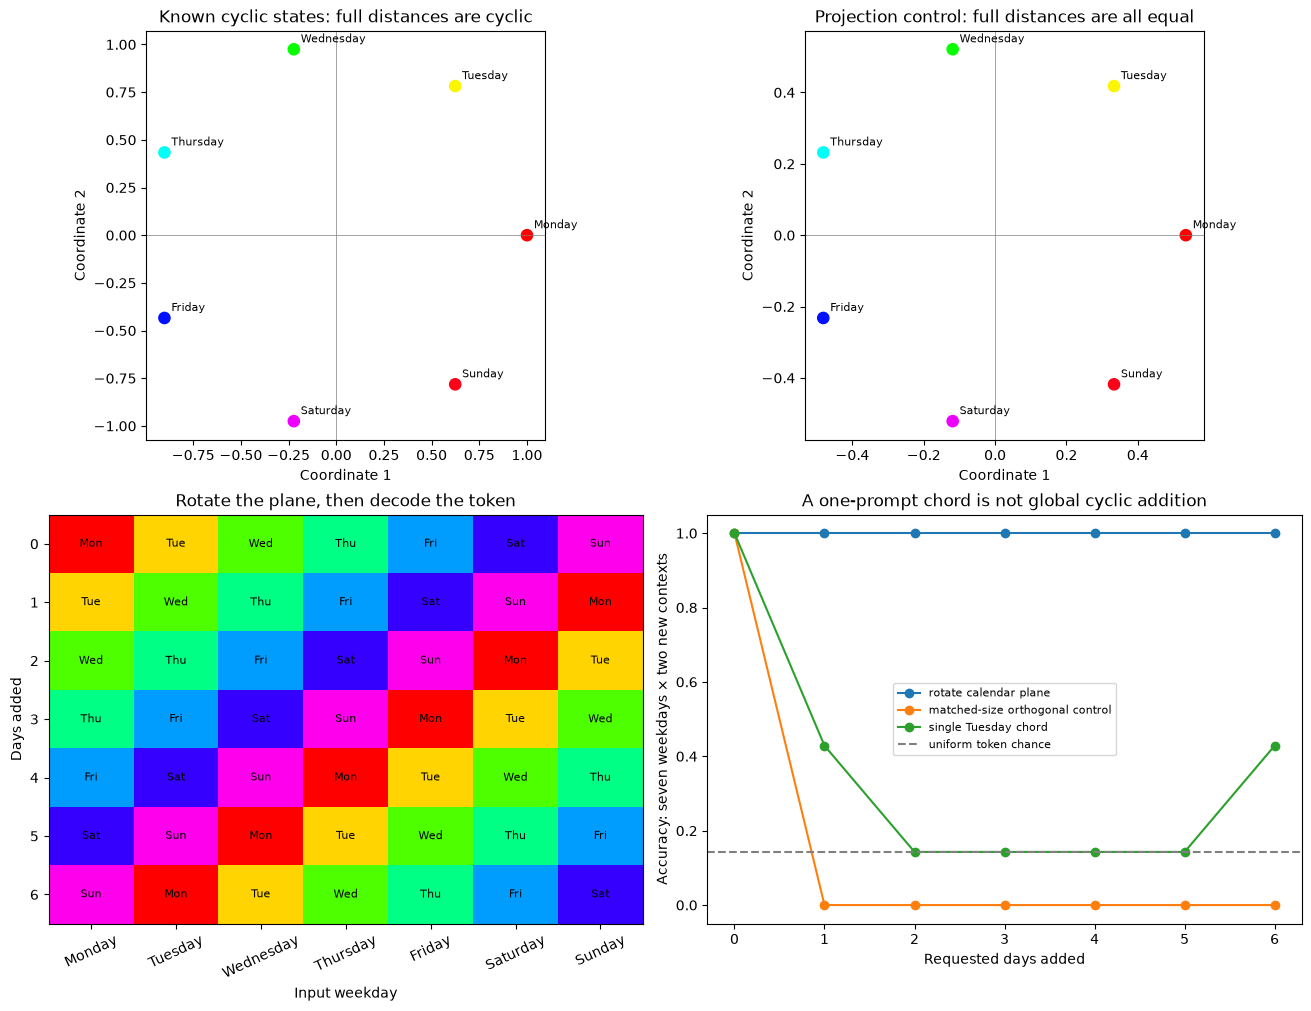

In [ ]:
# Use the frozen new contexts, not the training states or refitted evaluation axes.
calendar_hidden = evaluated_hidden.copy()
rotation_predictions = []
rotation_accuracy, wrong_accuracy, chord_accuracy = [], [], []
control_direction = np.array([0., 0., 0., 0., 0., 1.])
for days_added in range(7):
    changed = rotate_in_plane(calendar_hidden, fitted_basis, 2*np.pi*days_added/7)
    wrong = matched_wrong_direction(calendar_hidden, changed, control_direction)
    chord = chord_shift(calendar_hidden, fitted_basis, 7, 1, (1+days_added)%7)
    expected = (day_ids + days_added) % 7
    predictions = decode_cycle(changed, basis, 7)
    rotation_predictions.append(predictions[::2])  # one token per weekday for the display
    rotation_accuracy.append(np.mean(predictions == expected))
    wrong_accuracy.append(np.mean(decode_cycle(wrong, basis, 7) == expected))
    chord_accuracy.append(np.mean(decode_cycle(chord, basis, 7) == expected))
rotation_predictions = np.array(rotation_predictions)
fig, axes = plt.subplots(2, 2, figsize=(13, 10), constrained_layout=True)
utils.label_points(axes[0, 0], calendar_view, days, "Known cyclic states: full distances are cyclic")
utils.label_points(axes[0, 1], simplex_view, days, "Projection control: full distances are all equal")
utils.token_heatmap(axes[1, 0], rotation_predictions, days)
for name, scores in (("rotate calendar plane", rotation_accuracy),
                     ("matched-size orthogonal control", wrong_accuracy),
                     ("single Tuesday chord", chord_accuracy)):
    axes[1, 1].plot(range(7), scores, marker="o", label=name)
axes[1, 1].axhline(1/7, color="gray", ls="--", label="uniform token chance")
axes[1, 1].set(xlabel="Requested days added", ylabel="Accuracy: seven weekdays × two new contexts",
               title="A one-prompt chord is not global cyclic addition", ylim=(-.05, 1.05))
axes[1, 1].legend(fontsize=8)
plt.show()
print("Tuesday +2 =", days[rotation_predictions[2, 1]])
print("+2 accuracy, rotation / chord / wrong-plane:", rotation_accuracy[2], chord_accuracy[2], wrong_accuracy[2])
month_changed = rotate_in_plane(month_hidden, fitted_basis, 2*np.pi*2/12)
month_predictions = decode_cycle(month_changed, basis, 12)
print("12-month +2 accuracy:", np.mean(month_predictions == (month_ids+2)%12))

## Interpreting the result

The two top panels look cyclic, but only the left has cyclic distances in its full state
space. The lower-left panel decodes actual weekday names after a plane rotation; adding
two sends Tuesday to Thursday, and the same rule works across the seven inputs. The
single Tuesday chord succeeds on its source example but fails to implement the operation
globally. The orthogonal control has the same displacement size per row and fails for
nonzero offsets. At offset zero all operations correctly do nothing, so that control
success is expected and should remain visible.

The month organism uses the same plane with a different period and token bank. Its perfect
12-month accuracy is a result of the declared cyclic mechanism, not evidence that month
lengths are equal in the real calendar. Do not infer date arithmetic from month-index arithmetic.

<details><summary>Help - does this prove the ring is an irreducible feature?</summary>

No. It verifies the known cyclic computation and its implementation in this organism.
The cited paper's irreducibility analysis adds distributional criteria; a rank-two span,
a clean ring and a successful intervention do not by themselves implement those tests.
For real activations, also check prompt families, layer choice, nonlinear readouts, omitted
dimensions, fit selection and whether intervention effects generalize beyond selected examples.

</details>

## Summary of 3️⃣

Directions, translations and rotations implement different transformations. Ground a
geometric story in decoded outcomes across controlled examples, not one edited token.

# 4️⃣ Probe space and time, then inspect residuals

> ##### Learning Objectives
>
> - Implement an affine probe, MSE and residual calculation with frozen fits.
> - Separate an interpretable residual hypothesis from a validated scientific discovery.

## Coordinates can be linearly readable without being a world model

Fit $T=HW+b$ by least squares from TRAIN hidden states `(n,d)` and normalized coordinate
targets `(n,k)`. Add a constant design column, use `np.linalg.lstsq`, and return weights
`(d,k)` and bias `(k,)`. Evaluate them without refitting on new locations/dates. The targets
here are fictional map coordinates and centered year values in declared units, not tokens
or measured LLM activations. A successful fit is a readout statement, not evidence that a
model reasons spatially or temporally.

### Exercise - implement `fit_affine_probe`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10 minutes on this exercise.
> ```

Implement `fit_affine_probe` with the shapes, equation, edge cases and return contract described above.

In [ ]:
def fit_affine_probe(hidden, targets):
    raise NotImplementedError()


tests.test_fit_affine_probe(fit_affine_probe)

<details>
<summary>Hint</summary>

An affine fit needs an intercept even if a particular balanced fixture happens to have zero mean.

</details>

<details>
<summary>Help - what does this check establish?</summary>

Keep both preprocessing and coefficients frozen. Refitting on evaluated targets would answer a different, easier question.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_fit_affine_probe passed!</pre>

</details>


<details><summary>Solution</summary>

```python
def fit_affine_probe(hidden, targets):
    design = np.column_stack([hidden, np.ones(len(hidden))])
    coefficients = np.linalg.lstsq(design, targets, rcond=None)[0]
    return coefficients[:-1], coefficients[-1]
```
</details>

Return mean squared error over all entries of predicted and reference coordinates of
shape `(n,k)`. Every target axis is expressed in the declared normalized toy units. In a
real study, longitude, latitude and year have different meanings and scales: report
per-axis errors in physical units as well as any normalized aggregate. A single mixed-unit
MSE can be dominated by an arbitrary choice of year units.

### Exercise - implement `probe_mse`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10 minutes on this exercise.
> ```

Implement `probe_mse` with the shapes, equation, edge cases and return contract described above.

In [ ]:
def probe_mse(predicted, targets):
    raise NotImplementedError()


tests.test_probe_mse(probe_mse)

<details>
<summary>Hint</summary>

Square signed errors, then average every example and target coordinate.

</details>

<details>
<summary>Help - what does this check establish?</summary>

A metric is interpretable only with its units and denominator; small normalized MSE is not automatically small physical error.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_probe_mse passed!</pre>

</details>


<details><summary>Solution</summary>

```python
def probe_mse(predicted, targets):
    return np.mean((predicted - targets)**2)
```
</details>

## A microscope starts with what your current explanation misses

Suppose you regress hidden states from known coordinates with a TRAIN-fitted affine model.
For evaluated hidden states `(n,d)` and coordinates `(n,k)`, return
$R=H-(TW+b)$ using the supplied fixed weights `(k,d)` and bias `(d,)`. Do not refit inside
this function. A structured residual suggests an omitted factor, but could also reflect
nonlinearity, confounding or data error. The next exercise will test one candidate on
new coordinate combinations.

### Exercise - implement `residual_readout`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10 minutes on this exercise.
> ```

Implement `residual_readout` with the shapes, equation, edge cases and return contract described above.

In [ ]:
def residual_readout(hidden, coordinates, weights, bias):
    raise NotImplementedError()


tests.test_residual_readout(residual_readout)

<details>
<summary>Hint</summary>

Subtract the predicted hidden state, not the predicted target coordinates.

</details>

<details>
<summary>Help - what does this check establish?</summary>

Residual structure motivates a falsifiable hypothesis; it does not name a discovered concept by itself.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_residual_readout passed!</pre>

</details>


<details><summary>Solution</summary>

```python
def residual_readout(hidden, coordinates, weights, bias):
    return hidden - (coordinates @ weights + bias)
```
</details>

For normalized `(x,y,time)` coordinates `(n,3)`, return the candidate interaction `x*time`
as shape `(n,1)`. This is the specific microscope hypothesis to test, not an arbitrary
nonlinear feature search. We will fit its relationship to the unexplained hidden coordinate
on TRAIN and compare it with the original affine explanation on a fixed new grid. The
author constructed the organism with this term, so recovery is a known-answer exercise,
not a novel scientific discovery.

### Exercise - implement `interaction_feature`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10 minutes on this exercise.
> ```

Implement `interaction_feature` with the shapes, equation, edge cases and return contract described above.

In [ ]:
def interaction_feature(coordinates):
    raise NotImplementedError()


tests.test_interaction_feature(interaction_feature)

<details>
<summary>Hint</summary>

Preserve the feature axis so the same affine-probe interface can fit it.

</details>

<details>
<summary>Help - what does this check establish?</summary>

A changed-coordinate prediction is stronger than giving an evocative name to a training-set residual plot.

</details>

<details>
<summary>Expected output</summary>

<pre style="font-size: 14px">All tests in test_interaction_feature passed!</pre>

</details>


<details><summary>Solution</summary>

```python
def interaction_feature(coordinates):
    return (coordinates[:, 0] * coordinates[:, 2])[:, None]
```
</details>

In [ ]:
# Four fictional map corners and years1900/2000, each in two irrelevant contexts.
train_coordinates, world_hidden = [], []
for x in (-1., 1.):
    for y_coord in (-1., 1.):
        for time in (-1., 1.):
            for style in (-.2, .2):
                train_coordinates.append([x, y_coord, time])
                world_hidden.append([x+y_coord, x-y_coord, time, x*time, style, 0.])
train_coordinates = np.array(train_coordinates)
world_hidden = np.array(world_hidden)
evaluated_coordinates = np.array([[-.75, .5, -.5], [.25, -.5, .5], [.75, .25, .75]])
evaluated_world = np.array([[x+y_coord, x-y_coord, time, x*time, .7, 0.]
                            for x, y_coord, time in evaluated_coordinates])
probe_w, probe_b = fit_affine_probe(world_hidden, train_coordinates)
predicted_coordinates = evaluated_world @ probe_w + probe_b
# Fixed shuffled-target control: complement only the x target in TRAIN.
shuffled_targets = train_coordinates.copy(); shuffled_targets[:, 0] *= -1
shuffled_w, shuffled_b = fit_affine_probe(world_hidden, shuffled_targets)
print("Frozen coordinate probe MSE:", probe_mse(predicted_coordinates, evaluated_coordinates))
print("Shuffled-x target control MSE:", probe_mse(evaluated_world @ shuffled_w + shuffled_b, evaluated_coordinates))
hidden_w, hidden_b = fit_affine_probe(train_coordinates, world_hidden)
train_residual = residual_readout(world_hidden, train_coordinates, hidden_w, hidden_b)
evaluated_residual = residual_readout(evaluated_world, evaluated_coordinates, hidden_w, hidden_b)
interaction_w, interaction_b = fit_affine_probe(interaction_feature(train_coordinates), train_residual[:, 3:4])
predicted_residual = interaction_feature(evaluated_coordinates) @ interaction_w + interaction_b
print("x      y      year     actual residual   interaction forecast   affine-only forecast")
for point, actual, predicted in zip(evaluated_coordinates, evaluated_residual[:, 3], predicted_residual[:, 0]):
    print(f"{point[0]: .2f} {point[1]: .2f} {1950+50*point[2]:7.1f}       {actual: .4f}              {predicted: .4f}               0.0000")

<details><summary>Expected output</summary>

The frozen coordinate readout has MSE near float64 rounding; the shuffled-x control has
MSE approximately 0.5278 in normalized units. The residual coordinate values for the new
grid are `0.3750`, `0.1250` and `0.5625`; the TRAIN-fitted interaction hypothesis predicts
each of them, while the affine-only explanation predicts zero. The evaluated style is
0.7 rather than either TRAIN style, so nuisance invariance is checked without refitting.

</details>

## What this microscope did and did not discover

We began with known place/time coordinates, measured an unexplained hidden component,
proposed the specific product `x*time`, and checked a new grid with frozen coefficients.
That is a miniature concept-discovery workflow. It recovered a planted relation in a
transparent organism, not a new law of nature or a concept independently discovered in
a pretrained model. A real scientific application needs a model trained on actual scientific
data, a mechanism for generating candidate concepts, and predictions checked against
independent measurements or controlled interventions outside the model.

Gurnee and Tegmark probe Llama-2 representations of spatial and temporal entities across
several datasets and scales. Our fictional map/date states illustrate linear readout and
held-out coordinates, but they omit textual entity extraction, prompt variation and the
question of what the model actually learned. Do not turn an injected coordinate into an
empirical claim about LLM spatial or temporal knowledge.

## Try it yourself

Keep the visible weekday circle unchanged, but give the decoder an additional second
harmonic that the original plane intervention leaves untouched. Forecast whether a perfect
circle plot still guarantees correct +2 token edits. Change `second_harmonic_weight` from
0 to 3 in the cell below, keeping the +2 request fixed. This changes the causal readout's
dependence on omitted dimensions, not the random seed. Compare with the original zero-weight
condition and explain any mismatch between visible geometry and answer behavior.

In [ ]:
second_harmonic_weight = 0.0  # Try3.0 after recording a forecast.
first_codes = cyclic_coordinates(np.arange(7), 7)
second_codes = cyclic_coordinates(2*np.arange(7), 7)
shifted_primary = rotate_in_plane(first_codes, np.eye(2), 4*np.pi/7)
# The readout now consults a second, unedited circular code in omitted dimensions.
play_logits = shifted_primary @ first_codes.T + second_harmonic_weight * second_codes @ second_codes.T
play_tokens = np.argmax(play_logits, axis=-1)
print("New-readout +2 accuracy:", np.mean(play_tokens == (np.arange(7)+2)%7))
print("Input -> output:", list(zip(days, [days[index] for index in play_tokens])))

## Limitations and native bridge

This lesson does not load GPT-2, Mistral 7B, Llama 3 or Llama-2. Its phase basis, calendar
decoder and coordinate-generating rules are explicit constructions. There is no native
SAE clustering, empirical irreducibility analysis, prompt/token/layer extraction, learned
place/date representation, or independently validated scientific discovery. Its strength
is that every geometric and causal claim has an exact task-related oracle and a control.

To extend it to a real model, freeze the checkpoint, tokenizer and prompt families; split
entities and prompt templates before fitting; define extraction layers/positions and
coordinate units; fit centers/projections/probes only on TRAIN; retain failed views and
shuffled-label baselines. Compare full-space and projected distances, subspace stability
across prompt families, frozen decoding and matched-size interventions evaluated through
actual answer logits. The shape of a plot cannot decide which layer, prompt or hypothesis
should have been selected. Native evidence and human learner acceptance remain pending.

## Summary of 4️⃣

A probe is a measuring instrument with a fitted calibration. Residuals can suggest useful
hypotheses, but predictive and causal checks outside the selected view determine what the
instrument has actually told you.

# ☆ Bonus

## Anomaly hunt and further reading

The real ring and the projected simplex have different full-space distance structures.
Can you choose a *different* projection that reverses which plot looks more compelling?
Keep the distance and intervention audits fixed while you do so. Then ask what counts as
evidence for the continuous path between discrete named tokens, and what evidence would
distinguish an irreducible circular feature from a mixture of unrelated token features.

- [Engels et al., Not All Language Model Features Are One-Dimensionally Linear](https://arxiv.org/abs/2405.14860):
  multidimensional features, days/months, native interventions and irreducibility criteria.
- [Gurnee & Tegmark, Language Models Represent Space and Time](https://arxiv.org/abs/2310.02207):
  spatial/temporal probes on named entities in the Llama-2 family.
- [NumPy SVD documentation](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html):
  the row/column conventions used by the PCA implementation.
- [NumPy least squares documentation](https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html):
  the numerical oracle behind the small affine probe.

Record forecasts, confidence, prior exposure and the changed-readout prediction before
opening the public reference answers. This remains guided Practice rather than an unseen score.